# ECE 9611 Project - Phase 1
## Brain tumour classification from MRI images

**Group:** 3  
**Members:** Tianqi Ni, Yuchen Zhao  
**Dataset:** #9 Brain Tumor MRI ([Kaggle](https://www.kaggle.com/datasets/deeppythonist/brain-tumor-mri-dataset))

**Problem:** given one MRI image, predict which of four classes it belongs to: glioma, meningioma, pituitary tumour or no tumour.

**Target:** the class, taken from the folder name.
**Unit:** one 2D image, not one patient. The dataset has no patient IDs.
**Main metric:** macro-F1, so each class counts equally. The test set is not evaluated in this phase.

## 1. Setup

In [1]:
import hashlib
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, precision_recall_fscore_support
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [3]:
SEED = 42
SIZE = (64, 64)
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
DATA = Path("data")
SPLIT_FILE = DATA / "splits.csv"

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
BAR_COLOR = "#2a78b5"

## 2. Load and audit the data

Every image in `train/` and `test/` is opened once. Test images are only used here for the quality and duplicate checks.

In [4]:
rows = []
for path in sorted(DATA.glob("*/*/*.jpg")):
    img = Image.open(path)
    small = img.convert("L").resize(SIZE)  # fails here if a file is corrupt
    rows.append({"path": path.as_posix(), "source": path.parts[1], "label": path.parts[2],
                 "width": img.width, "height": img.height, "mode": img.mode,
                 "bytes": path.stat().st_size,
                 "hash": hashlib.md5(small.tobytes()).hexdigest()})
df = pd.DataFrame(rows)

print("Table 1. Images per class in the supplied folders")
counts = pd.crosstab(df["label"], df["source"])
counts["total"] = counts.sum(axis=1)
display(counts)

Table 1. Images per class in the supplied folders


source,test,train,total
label,,,
glioma,324,1297,1621
meningioma,355,1420,1775
notumor,400,1600,2000
pituitary,351,1406,1757


In [5]:
# missingness and basic quality
print("Table 2. Quality checks")
display(pd.Series({
    "Images": len(df),
    "Empty files": int((df["bytes"] == 0).sum()),
    "Missing labels": int(df["label"].isna().sum()),
    "Labels outside the 4 classes": int((~df["label"].isin(CLASSES)).sum()),
    "Distinct image sizes": len(df[["width", "height"]].drop_duplicates()),
    "Colour modes": ", ".join(sorted(df["mode"].unique())),
}).to_frame("Value"))
print("Every file opened without error, or the loop above would have stopped.")
print("No tabular fields means no missing values to fill. Patient ID, scanner and age are not supplied.")

Table 2. Quality checks


,Value
Images,7153
Empty files,0
Missing labels,0
Labels outside the 4 classes,0
Distinct image sizes,387
Colour modes,"L, P, RGB, RGBA"


Every file opened without error, or the loop above would have stopped.
No tabular fields means no missing values to fill. Patient ID, scanner and age are not supplied.


In [6]:
# gaps: do the numbers in the filenames skip anything?
df["file_id"] = df["path"].str.extract(r"-(\d+)\.jpg$")[0].astype(int)
gaps = df.groupby("label")["file_id"].agg(images="count", highest_id="max")
gaps["missing_ids"] = gaps["highest_id"] - gaps["images"]
print("Table 3. Filename numbering, train and test combined")
display(gaps)

Table 3. Filename numbering, train and test combined


,images,highest_id,missing_ids
label,,,
glioma,1621,1621,0
meningioma,1775,1775,0
notumor,2000,2000,0
pituitary,1757,1757,0


### Duplicates

Two files count as duplicates if they give the same 64x64 grayscale image, since that is what the models see. A copy in both train and test would be leakage, so the test copy is kept and the others are dropped. Files on disk are not changed.

In [7]:
by_hash = df.groupby("hash")
print("Redundant copies:", len(df) - df["hash"].nunique())
print("Duplicate groups:", int((by_hash.size() > 1).sum()))
print("Groups crossing train and test:", int((by_hash["source"].nunique() > 1).sum()))
print("Groups with conflicting labels:", int((by_hash["label"].nunique() > 1).sum()))

# "test" sorts before "train", so the test copy is the one kept
clean = df.sort_values(["source", "path"]).drop_duplicates("hash")
print("Images left:", len(clean))

Redundant copies: 556
Duplicate groups: 409
Groups crossing train and test: 140
Groups with conflicting labels: 0
Images left: 6597


## 3. Train / validation / test split

The cleaned `test/` folder stays as the test set. The rest is split 75/25 with stratification, which gives roughly 60/20/20 overall. The split is saved the first time and reloaded after that, so it stays frozen.

In [8]:
if SPLIT_FILE.exists():
    splits = pd.read_csv(SPLIT_FILE)
else:
    dev = clean[clean["source"] == "train"]
    tr, val = train_test_split(dev["path"], test_size=0.25, stratify=dev["label"], random_state=SEED)
    splits = clean[["path", "label"]].assign(split="test")
    splits.loc[splits["path"].isin(tr), "split"] = "train"
    splits.loc[splits["path"].isin(val), "split"] = "validation"
    splits.to_csv(SPLIT_FILE, index=False)

assert set(splits["path"]) == set(clean["path"])
clean = clean.merge(splits[["path", "split"]], on="path")

In [9]:
print("Table 4. Frozen split")
table = pd.crosstab(clean["label"], clean["split"])[["train", "validation", "test"]]
table.loc["total"] = table.sum()
display(table)
print("Percent of images:", (table.loc["total"] / len(clean) * 100).round(1).to_dict())

train = clean[clean["split"] == "train"]
val = clean[clean["split"] == "validation"]

Table 4. Frozen split


split,train,validation,test
label,,,
glioma,973,324,323
meningioma,889,296,346
notumor,999,333,374
pituitary,1042,348,350
total,3903,1301,1393


Percent of images: {'train': 59.2, 'validation': 19.7, 'test': 21.1}


## 4. Exploring the training images

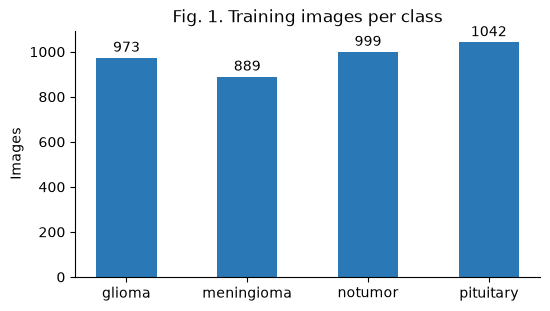

In [10]:
# Fig. 1
fig, ax = plt.subplots(figsize=(6, 3.2))
class_counts = train["label"].value_counts().reindex(CLASSES)
bars = ax.bar(CLASSES, class_counts, width=0.5, color=BAR_COLOR)
ax.bar_label(bars, padding=2)
ax.set(title="Fig. 1. Training images per class", ylabel="Images")
plt.show()

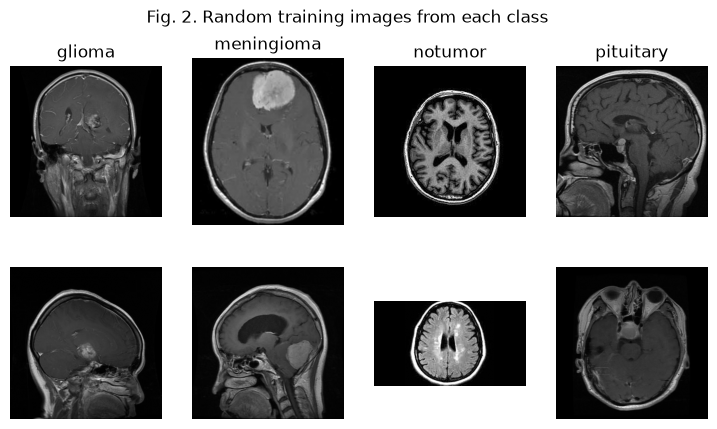

In [11]:
# Fig. 2
fig, axes = plt.subplots(2, 4, figsize=(9, 4.8))
for col, label in enumerate(CLASSES):
    samples = train[train["label"] == label].sample(2, random_state=SEED)
    for row, path in enumerate(samples["path"]):
        axes[row, col].imshow(Image.open(path).convert("L"), cmap="gray")
        axes[row, col].axis("off")
    axes[0, col].set_title(label)
fig.suptitle("Fig. 2. Random training images from each class")
plt.show()

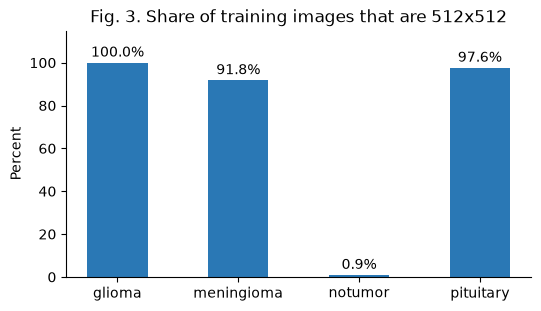

In [12]:
# Fig. 3
is_512 = (train["width"] == 512) & (train["height"] == 512)
share = is_512.groupby(train["label"]).mean().reindex(CLASSES) * 100

fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.bar(CLASSES, share, width=0.5, color=BAR_COLOR)
ax.bar_label(bars, fmt="%.1f%%", padding=2)
ax.set(title="Fig. 3. Share of training images that are 512x512", ylabel="Percent", ylim=(0, 115))
plt.show()

**What the figures show**

- Fig. 1: the classes are fairly balanced (889 to 1042 images), so accuracy is not badly misleading. Macro-F1 is still the main metric.
- Fig. 2: the images mix axial, coronal and sagittal views, and some are not square. A pixel-based model has to cope with all of that.
- Fig. 3: almost all tumour images are 512x512, but only 0.9% of `notumor` images are. This suggests the no-tumour images came from a different source, so a model could partly learn the source and not the anatomy. Resizing hides the size itself, but differences in image quality or framing may remain.

## 5. Preprocessing

Each image becomes 64x64 grayscale, flattened to 4096 values between 0 and 1. A plain resize is used because padding would add black bars that give away the original shape. Test features are not built in this phase.

In [13]:
def load_features(frame):
    images = [np.asarray(Image.open(p).convert("L").resize(SIZE), dtype=np.float32) for p in frame["path"]]
    return np.stack(images).reshape(len(images), -1) / 255

X_train, y_train = load_features(train), train["label"].to_numpy()
X_val, y_val = load_features(val), val["label"].to_numpy()
print("Train:", X_train.shape, "| Validation:", X_val.shape)
print("Missing pixels:", int(np.isnan(X_train).sum()))

Train: (3903, 4096) | Validation: (1301, 4096)
Missing pixels: 0


The imputer and scaler are fit on the training data only and then applied to validation. No pixels are missing, so the imputer has nothing to do here. It stays in so every model gets the same steps.

`make_model` puts the same two steps in front of any classifier. Inside cross-validation, they are then refit on each training fold.

In [14]:
def make_model(clf):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), clf)

prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(X_train)
print(f"Mean pixel after scaling - train: {prep.transform(X_train).mean():.4f}, validation: {prep.transform(X_val).mean():.4f}")

Mean pixel after scaling - train: 0.0000, validation: -0.0108


## 6. Baselines

All models get the same inputs and split and are scored with the same metrics on validation. The majority-class model is the reference to beat. Logistic Regression minimises cross-entropy. KNN has no training loss, so the models are compared on these metrics and not on a loss.

This first run uses the scikit-learn defaults: `C = 1` and `k = 5`.

In [15]:
def evaluate(name, model):
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - start

    start = time.perf_counter()
    pred = model.predict(X_val)
    infer_time = time.perf_counter() - start

    p, r, f1, _ = precision_recall_fscore_support(y_val, pred, average="macro", zero_division=0)
    row = {"model": name, "accuracy": accuracy_score(y_val, pred), "precision": p, "recall": r,
           "macro_f1": f1, "fit_s": fit_time, "infer_ms_per_image": infer_time / len(y_val) * 1000}
    return row, pred

In [16]:
default_models = {
    "Majority class": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (C=1)": make_model(LogisticRegression(C=1.0, max_iter=3000)),
    "KNN (k=5)": make_model(KNeighborsClassifier(n_neighbors=5)),
}
first = pd.DataFrame([evaluate(name, m)[0] for name, m in default_models.items()]).set_index("model")

print("Table 5. First validation results with default settings")
display(first[["accuracy", "precision", "recall", "macro_f1"]].round(4))

Table 5. First validation results with default settings


,accuracy,precision,recall,macro_f1
model,,,,
Majority class,0.2675,0.0669,0.2500,0.1055
Logistic Regression (C=1),0.8563,0.8529,0.8516,0.8518
KNN (k=5),0.8532,0.8620,0.8452,0.8435


**First look:** with default settings, both models are far better than the majority class. Macro-F1 is 0.852 for Logistic Regression and 0.844 for KNN, against 0.106. None of these settings are tuned yet, so section 7 checks whether regularization or a different `k` helps.

## 7. Cross-validation and regularization

3-fold CV on the training set only. For Logistic Regression, a smaller `C` means stronger L2 regularization. For KNN, a larger `k` means a smoother decision. The pipeline refits inside each fold, so the scaler never sees the fold it is scored on.

In [17]:
candidates = [("Logistic Regression", c, LogisticRegression(C=c, max_iter=3000)) for c in [0.001, 0.01, 0.1, 1]]
candidates += [("KNN", k, KNeighborsClassifier(n_neighbors=k)) for k in [1, 3, 5, 9]]

folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
rows = []
for name, value, clf in candidates:
    scores = cross_val_score(make_model(clf), X_train, y_train, cv=folds, scoring="f1_macro")
    rows.append({"model": name, "setting": value, "cv_macro_f1": scores.mean(), "std": scores.std()})
cv_results = pd.DataFrame(rows)

print("Table 6. 3-fold CV on training data (C for Logistic Regression, k for KNN)")
display(cv_results.round(4))

Table 6. 3-fold CV on training data (C for Logistic Regression, k for KNN)


,model,setting,cv_macro_f1,std
0,Logistic Regression,0.001,0.8379,0.0070
1,Logistic Regression,0.010,0.8518,0.0062
2,Logistic Regression,0.100,0.8520,0.0072
3,Logistic Regression,1.000,0.8386,0.0038
4,KNN,1.000,0.8843,0.0078
5,KNN,3.000,0.8264,0.0079
6,KNN,5.000,0.7911,0.0090
7,KNN,9.000,0.7639,0.0072


In [18]:
best = cv_results.loc[cv_results.groupby("model")["cv_macro_f1"].idxmax()].set_index("model")["setting"]
best_c, best_k = best["Logistic Regression"], int(best["KNN"])
print("Chosen C:", best_c, "| Chosen k:", best_k)

Chosen C: 0.1 | Chosen k: 1


**What CV shows**

- Regularization matters for Logistic Regression: F1 peaks around C = 0.01 to 0.1 (0.852) and is lower at C = 1 and C = 0.001 (0.84). The gap between C = 0.01 and 0.1 is smaller than the fold-to-fold variation, so those two are effectively tied.
- KNN gets steadily worse as k grows, from 0.884 at k = 1 to 0.764 at k = 9. That is unusual, because k = 1 normally overfits. It looks like many images have one very similar image in the training set, which section 9 comes back to.

## 8. Final comparison

Both models are refit with the values chosen by CV. Inference time is measured on validation because the test set stays untouched until the final stage.

In [19]:
models = {
    "Majority class": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_model(LogisticRegression(C=best_c, max_iter=3000)),
    "KNN": make_model(KNeighborsClassifier(n_neighbors=best_k)),
}
rows, preds = [], {}
for name, model in models.items():
    row, preds[name] = evaluate(name, model)
    rows.append(row)
results = pd.DataFrame(rows).set_index("model")

In [20]:
# only Logistic Regression learns weights; KNN just stores the training images
lr = models["Logistic Regression"][-1]
results["parameters"] = [0, lr.coef_.size + lr.intercept_.size, 0]
results["f1_gain_over_majority"] = results["macro_f1"] - results.loc["Majority class", "macro_f1"]
results["f1_gain_over_default"] = results["macro_f1"] - first["macro_f1"].to_numpy()

Path("artifacts").mkdir(exist_ok=True)
results.to_csv("artifacts/baseline_results.csv")
print(f"Table 7. Final validation comparison (seed {SEED}, C = {best_c}, k = {best_k})")
display(results.round(4))

Table 7. Final validation comparison (seed 42, C = 0.1, k = 1)


,accuracy,precision,recall,macro_f1,fit_s,infer_ms_per_image,parameters,f1_gain_over_majority,f1_gain_over_default
model,,,,,,,,,
Majority class,0.2675,0.0669,0.2500,0.1055,0.0017,0.0000,0,0.0000,0.0000
Logistic Regression,0.8647,0.8609,0.8602,0.8603,5.6269,0.0221,16388,0.7547,0.0084
KNN,0.9285,0.9283,0.9255,0.9259,1.2745,0.1942,0,0.8204,0.0825


### Where the models go wrong

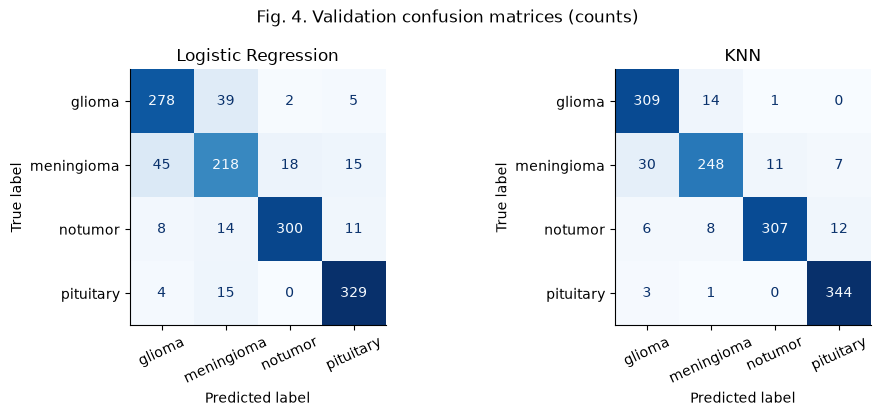

In [21]:
# Fig. 4
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, name in zip(axes, ["Logistic Regression", "KNN"]):
    ConfusionMatrixDisplay.from_predictions(y_val, preds[name], labels=CLASSES, cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("Fig. 4. Validation confusion matrices (counts)")
fig.tight_layout()
plt.show()

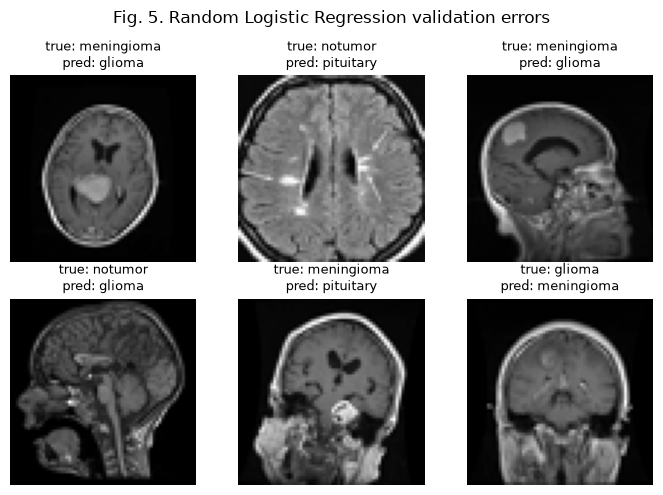

In [22]:
# Fig. 5: six random Logistic Regression errors, not hand-picked
errors = np.flatnonzero(preds["Logistic Regression"] != y_val)
wrong = np.random.default_rng(SEED).choice(errors, 6, replace=False)
fig, axes = plt.subplots(2, 3, figsize=(7, 5))
for ax, i in zip(axes.flat, wrong):
    ax.imshow(X_val[i].reshape(SIZE), cmap="gray")
    ax.set_title(f"true: {y_val[i]}\npred: {preds['Logistic Regression'][i]}", fontsize=9)
    ax.axis("off")
fig.suptitle("Fig. 5. Random Logistic Regression validation errors")
fig.tight_layout()
plt.show()

## 9. Conclusion and next risk

**Conclusion:** simple pixel models are far better than guessing on this data. Validation macro-F1 goes from 0.106 for the majority class to 0.860 for Logistic Regression (C = 0.1) and 0.926 for KNN (k = 1), as Table 7 shows. Tuning by CV helped Logistic Regression a little (+0.008 over the default) and KNN a lot (+0.083).

Glioma vs meningioma is the hardest pair and makes up about half of all errors in both models (84 of 176 for Logistic Regression, 44 of 93 for KNN). Meningioma has the lowest recall in both (74% and 84%).

KNN has the best score, but we would not treat it as the better model yet because of the risk below. Logistic Regression is also much faster per image at prediction, though KNN is quicker to fit.

**Unresolved risk:** near-duplicates across the splits. Only images that match exactly at 64x64 were removed, and there are no patient IDs, so neighbouring slices from one patient could still sit in both train and validation. KNN doing best at k = 1 fits this explanation, but it does not prove it. If it is true, the validation scores here are too optimistic for new patients. The source difference in Fig. 3 could inflate them in a similar way.

**Next step:** measure how close each validation image is to its nearest training image and look at the closest pairs, before any model is selected in Phase 2.

## 10. Smoke test

Quick checks on the split, preprocessing and fitted models. Nothing is retrained, so they run in under a second once the cells above have run.

In [23]:
test = clean[clean["split"] == "test"]
assert (len(train), len(val), len(test)) == (3903, 1301, 1393)
assert not set(train["hash"]) & set(val["hash"])
assert not set(train["hash"]) & set(test["hash"])
assert not set(val["hash"]) & set(test["hash"])

# scaler was fit on training data only
assert np.allclose(prep[-1].mean_, X_train.mean(axis=0, dtype=np.float64))
assert np.isfinite(prep.transform(X_val)).all()
# the scaler inside the final model was also fit on training data only
scaler = models["Logistic Regression"].named_steps["standardscaler"]
assert np.allclose(scaler.mean_, X_train.mean(axis=0, dtype=np.float64))
assert len(models["KNN"].predict(X_val[:5])) == 5
assert "X_test" not in globals()
print("All checks passed. Test features were never built.")

All checks passed. Test features were never built.


## Contributions and references

- **Tianqi Ni:** data audit, duplicates, split, exploratory figures, preprocessing
- **Yuchen Zhao:** baselines and model comparison

AI disclosure: Used Codex and Claude for help with the code and write-up.